# 02 — La base de series del Tema 1 (bloque 2)

Este notebook recorre la **base de series** que alimenta `get_serie(id, fecha)`: la unión de `data/raw`
de la Fase 1, los sustitutos y componentes descargados de FRED/ALFRED y las fuentes académicas (Ken French,
Shiller, Goyal-Welch y el FSI de la OFR). Cada fila lleva su `fecha_publicacion`, la primera fecha de
decisión (16:30 de Nueva York) en que el valor se conocía, fijada con la regla de su método.

La base vive fuera del repositorio, en `<corpus>/mercados_series/series/base_series.parquet` (licencias de
FRED, ICE, S&P, Moody's...). Con `EJECUTAR = False` el notebook solo la lee; si no existe, avisa y para.
Para construirla: `python -m ingesta.mercados_series construir-base --sin-red` (alrededor de un minuto).

Las cifras que cita el texto proceden de las salidas de las celdas. Las salidas no muestran valores de
las series (licencias): solo fechas, recuentos y metadatos.

Secciones:

1. Inventario: series por fuente, frecuencia, método y estado.
2. Cobertura de todas las series (diagrama de Gantt, color por método).
3. Cobertura por década y familia (mapa de calor).
4. Reparto por método de publicación y estado.
5. Retraso de publicación por método.
6. Series retiradas o capadas y sus sustitutos (incluido el archivo de las OAS de ICE BofA).
7. El mismo día visto por `get_serie`: 10 series clave el 2008-09-15 y el 2020-03-16 (fechas y métodos,
   sin valores).
8. Fechas de publicación medidas en ALFRED (excepciones), índices reconstruidos y anomalías anotadas.
9. Conclusiones.

*This product uses the FRED® API but is not endorsed or certified by the Federal Reserve Bank of St. Louis.*

In [1]:
%matplotlib inline
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import display

from ingesta.comun.rutas import resultados_dir
from ingesta.mercados_series import almacen, base, tools
from ingesta.mercados_series import catalogo as cat_mod

try:
    from regimenes import viz
    viz.use_house_style()
except Exception:  # sin el paquete de la Fase 1: estilo por defecto de matplotlib
    pass
plt.rcParams['figure.dpi'] = 100
warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.width', 160)
pd.set_option('display.max_colwidth', 70)
pd.set_option('display.max_rows', 60)

EJECUTAR = False   # True: reconstruye la base sin red (crudos ya descargados y data/raw) antes de leerla
RUTA = almacen.ruta_series()
if EJECUTAR:
    resumen, _ = base.construir_base(sin_red=True, registro=print)
    print(json.dumps(base._np_a_py(resumen.como_dict())['por_cargador'], ensure_ascii=False))
if not RUTA.exists():
    raise FileNotFoundError(f'No hay base en {RUTA}. Constrúyela con: '
                            'python -m ingesta.mercados_series construir-base --sin-red (o EJECUTAR = True)')

BASE = almacen.leer_series()
CAT = cat_mod.cargar_catalogo()
COB = base.cobertura(BASE, CAT)
print(f'{RUTA}: {len(BASE):,} filas, {BASE["serie"].nunique()} series, '
      f'{int(BASE["valor"].isna().sum()):,} huecos declarados (valor nulo con nota)')

# Paleta categórica fija por método (orden estable: el color sigue al método, no a su rango).
METODOS = ['cierre_mercado', 'calendario', 'lag_fijo', 'fichero', 'derivada', 'vintage_exacto']
COLOR_METODO = dict(zip(METODOS, ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300']))
C_GRIS = '#8a8984'

D:\tfm_corpus\mercados_series\series\base_series.parquet: 1,440,209 filas, 190 series, 219 huecos declarados (valor nulo con nota)


## 1. Inventario

Una serie es un id del catálogo (`config/catalogo_series.yaml`) con prefijo de fuente. Entran los estados
cargables (activa, retirada, capada, duplicada) y el WEI (`pendiente_alfred`, cargado con todas sus vintages
de ALFRED). Las ETF de yfinance descargadas por la Fase 1 con `auto_adjust=True` quedan fuera
(`excluida_ajustada`): sus niveles se reajustaron a posteriori y se servirán por `get_precios`.

In [2]:
inv = COB.copy()
por_fuente = (inv.pivot_table(index='fuente', columns='metodo', values='id', aggfunc='count', fill_value=0)
              .reindex(columns=[m for m in METODOS if m in set(inv['metodo'])]))
por_fuente['total'] = por_fuente.sum(axis=1)
por_fuente.loc['total'] = por_fuente.sum()
print('Series por fuente y método de publicación')
display(por_fuente)

por_frec = inv.pivot_table(index='frecuencia', columns='estado', values='id', aggfunc='count', fill_value=0)
por_frec['total'] = por_frec.sum(axis=1)
print('Series por frecuencia y estado')
display(por_frec)

excluidas = sum(1 for x in CAT.values() if x['estado'] == 'excluida_ajustada')
print(f'Catálogo: {len(CAT)} entradas; base: {len(inv)} series; fuera de la base: {excluidas} ETF ajustadas')
filas_fuente = BASE['fuente'].value_counts().rename('filas').to_frame()
filas_fuente['huecos'] = BASE[BASE['valor'].isna()]['fuente'].value_counts()
display(filas_fuente.fillna(0).astype(int))

Series por fuente y método de publicación


metodo,cierre_mercado,calendario,lag_fijo,fichero,derivada,vintage_exacto,total
fuente,,,,,,,
calculo_propio,0,0,0,0,4,0,4
datahub,0,0,0,2,0,0,2
fred_alfred,12,52,48,0,0,1,113
goyal_welch,0,0,0,17,0,0,17
ken_french,0,0,0,17,0,0,17
ofr_fsi,0,0,5,0,0,0,5
shiller,0,0,0,6,0,0,6
yfinance,26,0,0,0,0,0,26
total,38,52,53,42,4,1,190


Series por frecuencia y estado


estado,activa,capada,duplicada,pendiente_alfred,retirada,total
frecuencia,,,,,,
diaria,98,8,3,0,8,117
mensual,54,0,4,0,3,61
semanal,7,0,0,1,0,8
trimestral,3,0,0,0,1,4


Catálogo: 214 entradas; base: 190 series; fuera de la base: 24 ETF ajustadas


,filas,huecos
fuente,,
fred_alfred,684006,219
ken_french,359653,0
yfinance,276787,0
calculo_propio,48411,0
ofr_fsi,33880,0
goyal_welch,23644,0
shiller,11084,0
datahub,2744,0


## 2. Cobertura de todas las series

Cada línea va de la primera a la última fecha de referencia con valor de una serie. Para que las etiquetas
se lean, dos figuras: las series diarias y el resto (semanales, mensuales, trimestrales y anuales),
agrupadas por familia y ordenadas por inicio.
El color es el método con el que se fecha su publicación. Las series más largas son las mensuales
académicas y macro; las de mercado diarias empiezan en general en la segunda mitad del siglo XX; las OAS de
ICE BofA solo cubren los últimos tres años (sección 6).

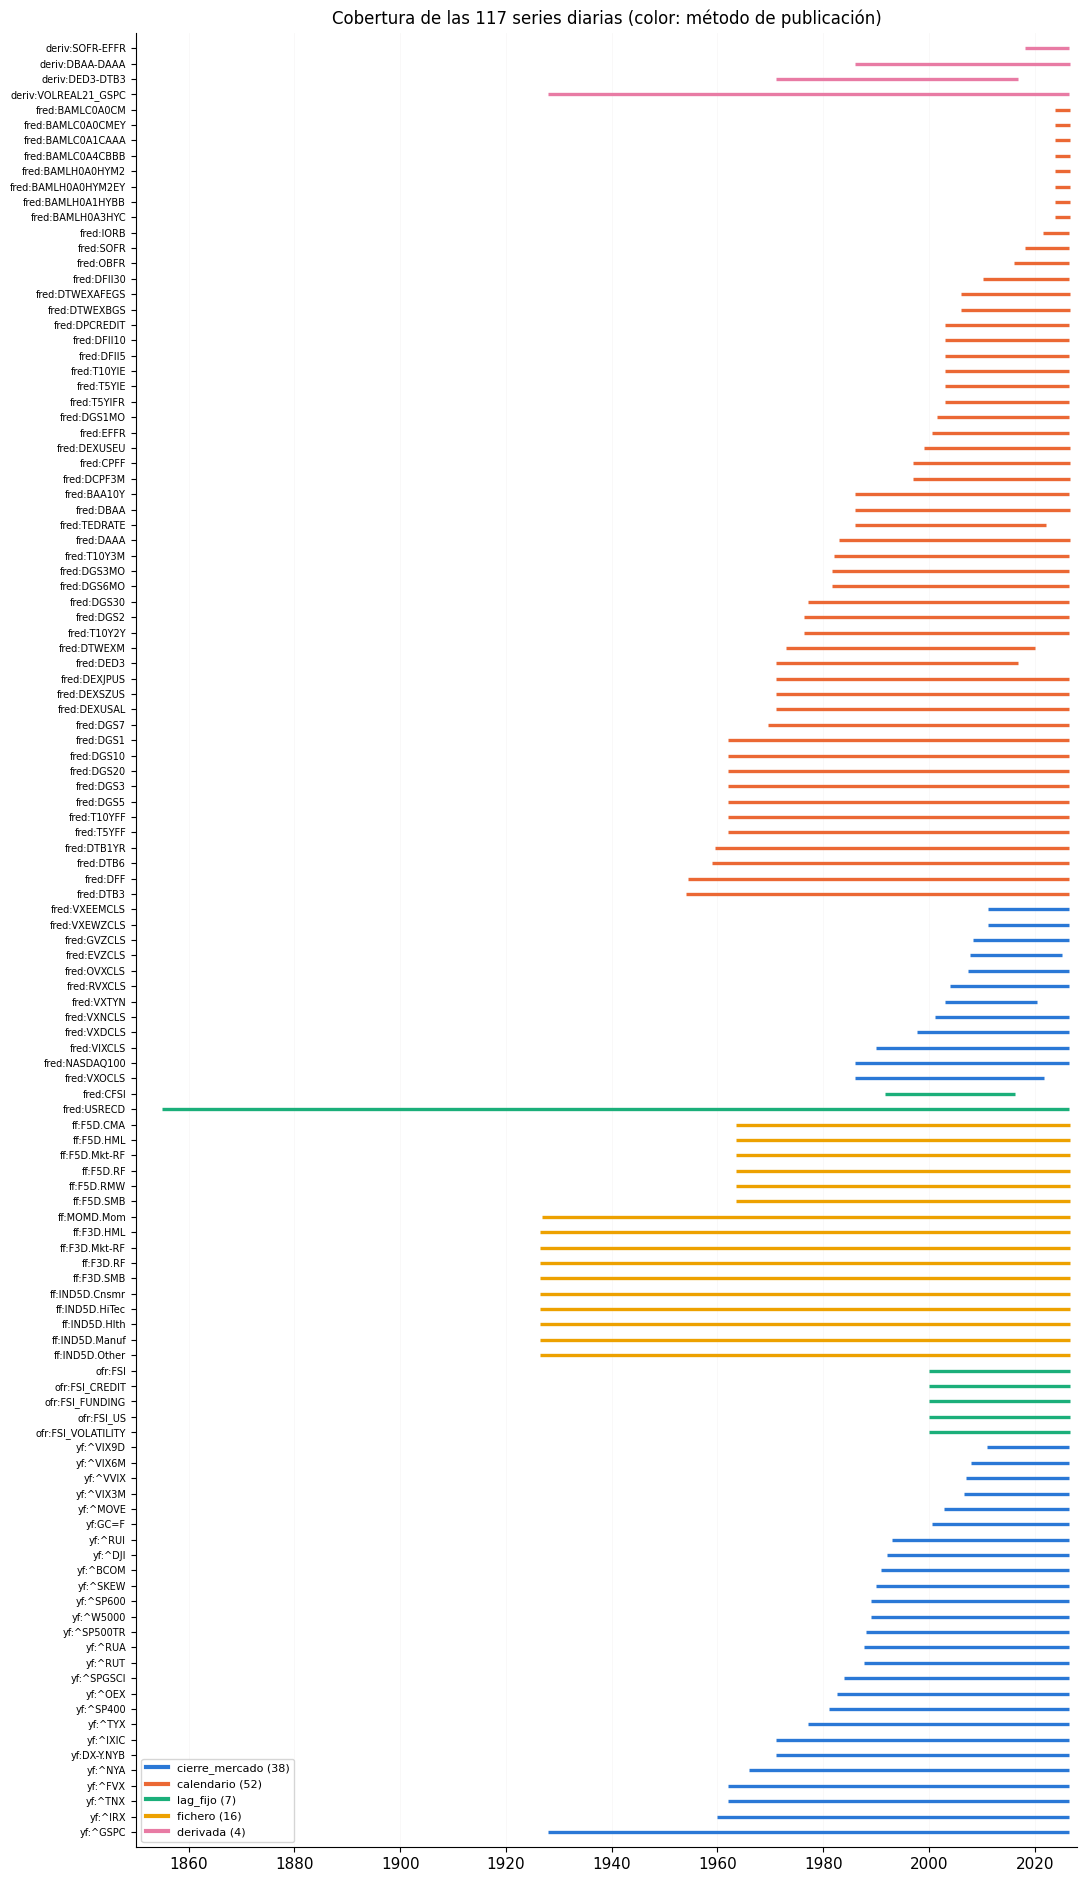

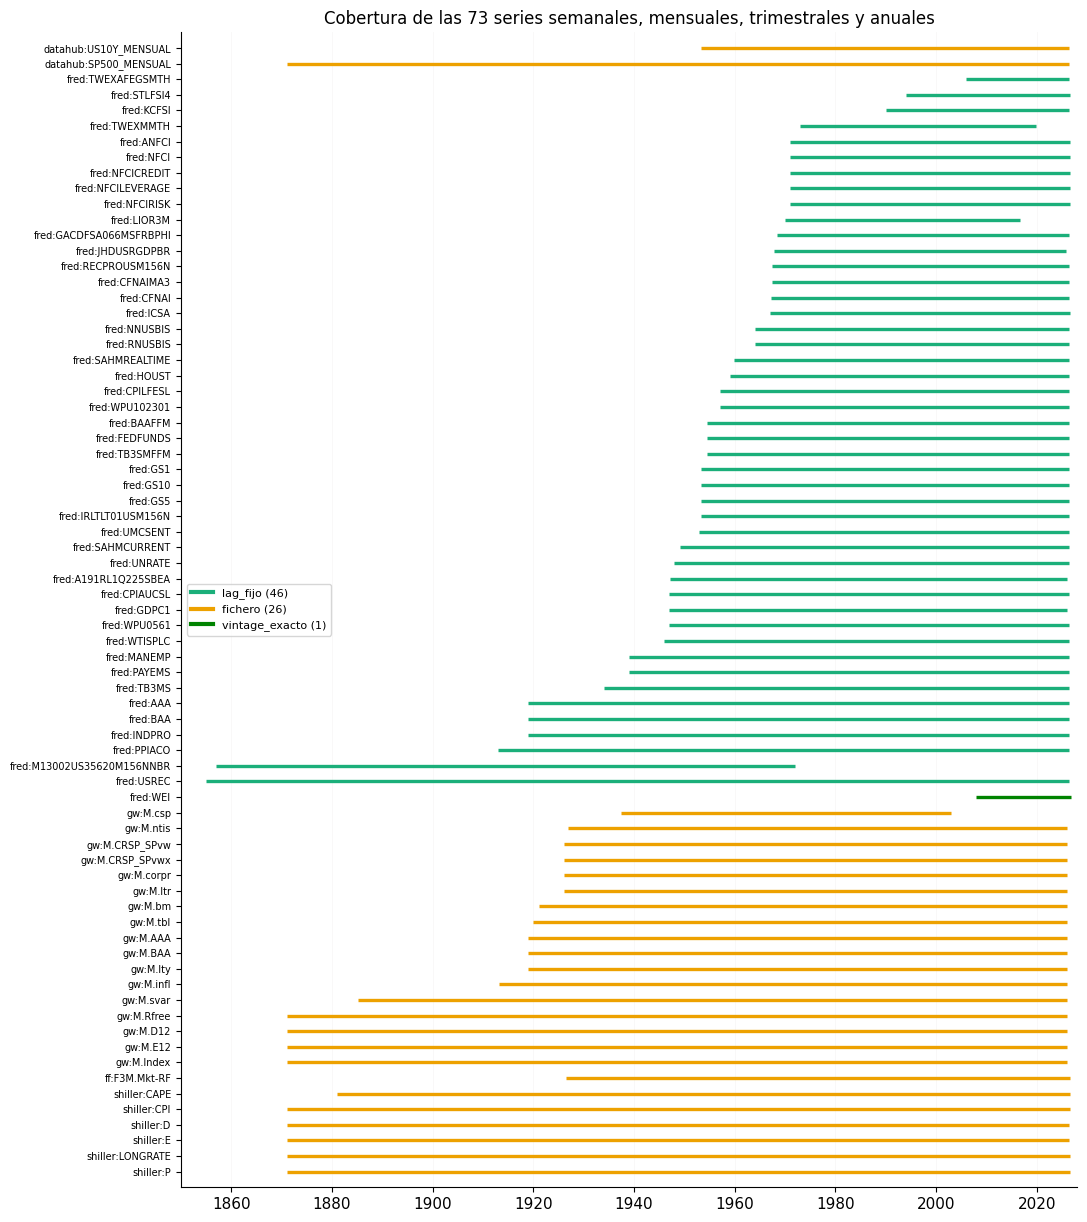

In [3]:
# Agrupadas por fuente y método (la familia de uso se define en la sección 3).
def gantt(g, titulo, leyenda_loc='lower left'):
    g = g.sort_values(['grupo', 'inicio', 'id'], ascending=[True, False, True]).reset_index(drop=True)
    fig, ax = plt.subplots(figsize=(11, 0.15 * len(g) + 1.4))
    for i, f in g.iterrows():
        ax.hlines(i, f['inicio'], f['fin'], color=COLOR_METODO[f['metodo']], lw=2.4)
    ax.set_yticks(range(len(g)))
    ax.set_yticklabels(g['id'], fontsize=7)
    ax.set_ylim(-1, len(g))
    ax.invert_yaxis()
    ax.set_xlim(pd.Timestamp('1850-01-01'), pd.Timestamp('2028-01-01'))
    ax.grid(axis='x', color='#e3e2de', lw=0.6)
    ax.grid(axis='y', visible=False)
    ax.set_title(titulo)
    leyenda = [Line2D([0], [0], color=COLOR_METODO[m], lw=3, label=f'{m} ({int((g["metodo"] == m).sum())})')
               for m in METODOS if (g['metodo'] == m).any()]
    ax.legend(handles=leyenda, loc=leyenda_loc, fontsize=8, frameon=True)
    plt.tight_layout()
    plt.show()


g = COB.dropna(subset=['inicio']).assign(inicio=lambda d: pd.to_datetime(d['inicio']),
                                           fin=lambda d: pd.to_datetime(d['fin']),
                                           grupo=lambda d: d['fuente'] + ' / ' + d['metodo'])
diarias = g[g['frecuencia'] == 'diaria']
otras = g[g['frecuencia'] != 'diaria']
gantt(diarias, f'Cobertura de las {len(diarias)} series diarias (color: método de publicación)')
gantt(otras, f'Cobertura de las {len(otras)} series semanales, mensuales, trimestrales y anuales',
      leyenda_loc='center left')

## 3. Cobertura por década y familia

Familias de uso (no de proveedor). Cada celda es el porcentaje de series de la familia con algún valor en
esa década; el número en la celda es cuántas series lo tienen.

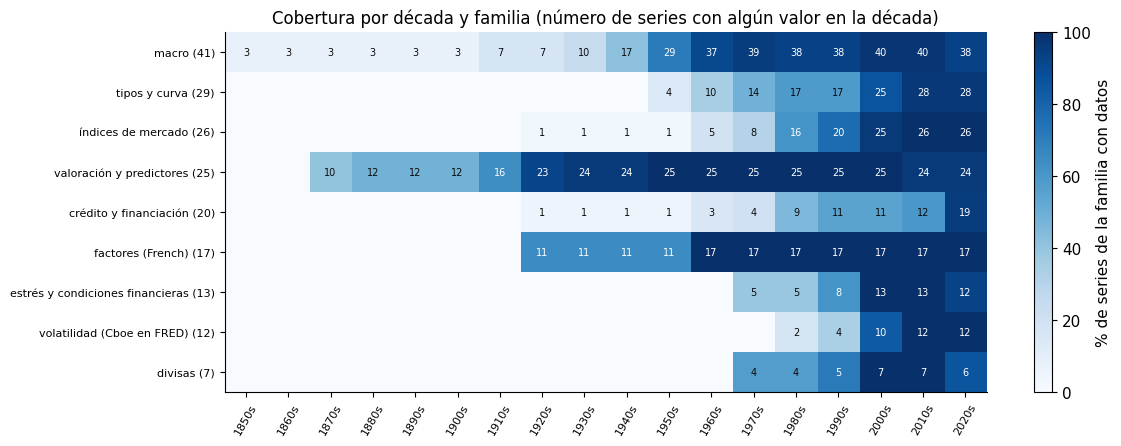

In [4]:
def familia(sid):
    e = CAT[sid]
    pub = e.get('publicador')
    if e['fuente'] == 'yfinance':
        return 'índices de mercado'
    if e['fuente'] == 'ken_french':
        return 'factores (French)'
    if e['fuente'] in ('goyal_welch', 'shiller', 'datahub'):
        return 'valoración y predictores'
    if e['fuente'] == 'ofr_fsi' or 'FCI' in sid or 'FSI' in sid:
        return 'estrés y condiciones financieras'
    if e['fuente'] == 'calculo_propio' or pub in ('moodys', 'ice_bofa_fred', 'fred_calculadas_dia_siguiente', 'fed_cp'):
        return 'crédito y financiación'
    if e['metodo'] == 'cierre_mercado':
        return 'volatilidad (Cboe en FRED)'
    if pub == 'fed_h10':
        return 'divisas'
    if pub in ('fed_h15', 'fred_tesoro_calculadas', 'nyfed_effr', 'nyfed_sofr'):
        return 'tipos y curva'
    return 'macro'

COB['familia'] = COB['id'].map(familia)
decadas = list(range(1850, 2030, 10))
filas = []
for _, f in COB.dropna(subset=['inicio']).iterrows():
    ini, fin = pd.Timestamp(f['inicio']).year, pd.Timestamp(f['fin']).year
    for d in decadas:
        filas.append({'familia': f['familia'], 'decada': d, 'cubre': int(ini <= d + 9 and fin >= d)})
cubre = pd.DataFrame(filas)
n = cubre.pivot_table(index='familia', columns='decada', values='cubre', aggfunc='sum', fill_value=0)
total = COB.groupby('familia').size()
n = n.loc[total.sort_values(ascending=False).index, decadas]
pct = n.div(total.loc[n.index], axis=0) * 100

fig, ax = plt.subplots(figsize=(12, 4.6))
im = ax.imshow(pct.to_numpy(), cmap='Blues', vmin=0, vmax=100, aspect='auto')
ax.set_xticks(range(len(pct.columns)))
ax.set_xticklabels([f'{d}s' for d in pct.columns], rotation=60, fontsize=8)
ax.set_yticks(range(len(pct.index)))
ax.set_yticklabels([f'{fam} ({total[fam]})' for fam in pct.index], fontsize=8)
for i in range(pct.shape[0]):
    for j in range(pct.shape[1]):
        v = int(n.iloc[i, j])
        if v:
            ax.text(j, i, v, ha='center', va='center', fontsize=7,
                    color='white' if pct.iloc[i, j] > 60 else '#0b0b0b')
ax.grid(False)
fig.colorbar(im, ax=ax, label='% de series de la familia con datos')
ax.set_title('Cobertura por década y familia (número de series con algún valor en la década)')
plt.tight_layout()
plt.show()

## 4. Reparto por método de publicación y estado

- `cierre_mercado`: cierre del mercado + 30 min (`config/mercados.yaml`): NYSE 16:00 → mismo día; Cboe,
  CME e ICE (DXY) → día siguiente.
- `calendario`: hora del publicador (`publicaciones.yaml`): H.15 el hábil siguiente a las 16:15, H.10 el lunes
  siguiente, Moody's D+1 a las 12:00, ICE en FRED D+1 a las 09:15...
- `lag_fijo`: fin del periodo + retraso declarado de `config/lags.yaml` (copia congelada de `LAG_PUBLICACION`
  de la Fase 1 y adicionales con justificación); solo se conoce el día.
- `fichero`: salida del fichero académico (French fin de mes + 45 días, Goyal-Welch 1 de agosto del año
  siguiente, Shiller día 1 de M+2), con la cota de las ediciones archivadas.
- `derivada`: la máxima de sus componentes (`contrato.fecha_publicacion_derivada`).
- `vintage_exacto`: la fecha de cada vintage de ALFRED (WEI).

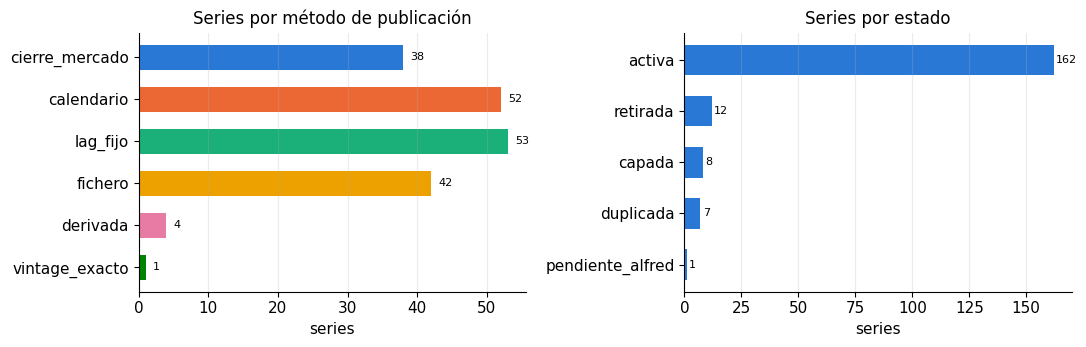

estado,activa,capada,duplicada,pendiente_alfred,retirada,total
metodo,,,,,,
calendario,41,8,0,0,3,52
cierre_mercado,35,0,0,0,3,38
derivada,3,0,0,0,1,4
fichero,35,0,6,0,1,42
lag_fijo,48,0,1,0,4,53
vintage_exacto,0,0,0,1,0,1
total,162,8,7,1,12,190


In [5]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 3.6))
m = COB['metodo'].value_counts().reindex([x for x in METODOS if x in set(COB['metodo'])])
ax = ejes[0]
ax.barh(m.index[::-1], m.values[::-1], color=[COLOR_METODO[x] for x in m.index[::-1]], height=0.6)
for y, v in enumerate(m.values[::-1]):
    ax.text(v + 1, y, str(v), va='center', fontsize=8)
ax.set_title('Series por método de publicación')
ax.set_xlabel('series')
e = COB['estado'].value_counts()
ax = ejes[1]
ax.barh(e.index[::-1], e.values[::-1], color='#2a78d6', height=0.6)
for y, v in enumerate(e.values[::-1]):
    ax.text(v + 1, y, str(v), va='center', fontsize=8)
ax.set_title('Series por estado')
ax.set_xlabel('series')
for ax in ejes:
    ax.grid(axis='y', visible=False)
plt.tight_layout()
plt.show()
display(pd.crosstab(COB['metodo'], COB['estado'], margins=True, margins_name='total'))

## 5. Retraso de publicación por método

Retraso = `fecha_publicacion − fecha_referencia` en días naturales, sobre la primera publicación de cada
periodo (en una mensual, la referencia es el día 1 del mes: un mes que se publica el día 1 de M+2 suma unos
60 días). Escala logarítmica (días + 1). La caja resume todas las filas del método; los puntos son la
mediana de cada serie.

Dos colas largas son deliberadas: el WEI (`vintage_exacto`) solo tiene vintages en ALFRED desde el
2020-04-16, así que las semanas de 2008 a 2020 no se ven hasta esa fecha; y las recesiones del NBER
(`USREC`, `USRECD`, `lag_fijo` de 24 meses) se fechan con el retraso máximo del comité de fechado.

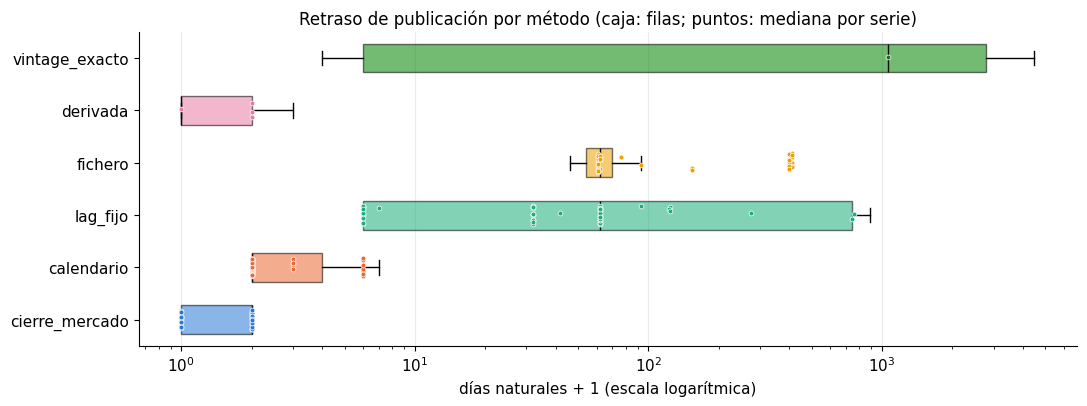

,count,min,50%,90%,max
metodo,,,,,
cierre_mercado,350372,0.0,1.0,1.0,1.0
calendario,474301,1.0,1.0,5.0,167.0
lag_fijo,158352,5.0,61.0,754.0,889.0
fichero,397125,45.0,61.0,74.0,578.0
derivada,48411,0.0,0.0,3.0,162.0
vintage_exacto,979,3.0,1062.0,3800.4,4485.0


,id,metodo,frecuencia,lag_mediano_dias,lag_min_dias,lag_max_dias
132,fred:WEI,vintage_exacto,semanal,1062.0,3,4485
123,fred:USREC,lag_fijo,mensual,760.0,757,889
124,fred:USRECD,lag_fijo,diaria,745.0,730,889
149,gw:M.lty,fichero,mensual,411.5,243,578
141,gw:M.E12,fichero,mensual,411.5,243,578
140,gw:M.D12,fichero,mensual,411.5,243,578
138,gw:M.CRSP_SPvw,fichero,mensual,411.5,243,578
148,gw:M.ltr,fichero,mensual,411.5,243,578
145,gw:M.corpr,fichero,mensual,411.5,243,578
152,gw:M.tbl,fichero,mensual,411.5,243,578


In [6]:
orden = BASE.sort_values(['serie', 'fecha_referencia', 'fecha_publicacion'], kind='mergesort')
primera = orden.drop_duplicates(['serie', 'fecha_referencia'], keep='first')
lag = (primera['fecha_publicacion'] - primera['fecha_referencia']).dt.days
lag_m = pd.DataFrame({'metodo': primera['metodo_publicacion'].to_numpy(), 'lag': lag.to_numpy()})
presentes = [x for x in METODOS if x in set(lag_m['metodo'])]

fig, ax = plt.subplots(figsize=(11, 4.2))
datos = [lag_m.loc[lag_m['metodo'] == x, 'lag'].to_numpy() + 1 for x in presentes]
cajas = ax.boxplot(datos, vert=False, showfliers=False, widths=0.55, patch_artist=True,
                   medianprops={'color': '#0b0b0b'})
for caja, x in zip(cajas['boxes'], presentes):
    caja.set_facecolor(COLOR_METODO[x])
    caja.set_alpha(0.55)
rng = np.random.default_rng(0)
for i, x in enumerate(presentes, start=1):
    med = COB.loc[COB['metodo'] == x, 'lag_mediano_dias'].to_numpy() + 1
    ax.scatter(med, i + rng.uniform(-0.18, 0.18, len(med)), s=12, color=COLOR_METODO[x],
               edgecolor='white', linewidth=0.5, zorder=3)
ax.set_xscale('log')
ax.set_yticks(range(1, len(presentes) + 1))
ax.set_yticklabels(presentes)
ax.set_xlabel('días naturales + 1 (escala logarítmica)')
ax.set_title('Retraso de publicación por método (caja: filas; puntos: mediana por serie)')
ax.grid(axis='y', visible=False)
plt.tight_layout()
plt.show()

resumen_lag = lag_m.groupby('metodo')['lag'].describe(percentiles=[0.5, 0.9])[['count', 'min', '50%', '90%', 'max']]
display(resumen_lag.reindex(presentes).astype({'count': int}))
display(COB.sort_values('lag_mediano_dias', ascending=False)
        [['id', 'metodo', 'frecuencia', 'lag_mediano_dias', 'lag_min_dias', 'lag_max_dias']].head(10))

## 6. Series retiradas o capadas y sus sustitutos

Una serie **retirada** dejó de publicarse (LIBOR, TED, el eurodólar de H.15, VXO...): entra con su
historia y el catálogo apunta a su `sucesor` cuando lo hay. Una serie **capada** sigue viva, pero la fuente
solo sirve una ventana: las OAS de ICE BofA en FRED empiezan hoy el 2023-10-10 (medido; que el recorte
fuera en abril de 2026 lo dice la Fase 1, no una medición de este bloque) y ni FRED ni ALFRED conservan el
historial anterior (apartado siguiente). El gráfico enlaza cada retirada con
su sucesor; en gris, la serie que se retira.

,id,estado,frecuencia,inicio,fin,n_obs,sucesor,sucesor_inicio,sucesor_fin
0,fred:BAMLC0A0CM,capada,diaria,2023-10-10,2026-10-08,785,None,NaN,NaN
1,fred:BAMLC0A0CMEY,capada,diaria,2023-10-10,2026-10-08,785,None,NaN,NaN
2,fred:BAMLC0A1CAAA,capada,diaria,2023-10-10,2026-10-08,786,None,NaN,NaN
3,fred:BAMLC0A4CBBB,capada,diaria,2023-10-10,2026-10-08,786,None,NaN,NaN
4,fred:BAMLH0A0HYM2,capada,diaria,2023-10-10,2026-10-08,786,None,NaN,NaN
5,fred:BAMLH0A0HYM2EY,capada,diaria,2023-10-10,2026-10-08,786,None,NaN,NaN
6,fred:BAMLH0A1HYBB,capada,diaria,2023-10-10,2026-10-08,786,None,NaN,NaN
7,fred:BAMLH0A3HYC,capada,diaria,2023-10-10,2026-10-08,786,None,NaN,NaN
8,fred:M13002US35620M156NNBR,retirada,mensual,1857-01-01,1971-12-01,1380,None,NaN,NaN
9,gw:M.csp,retirada,mensual,1937-05-01,2002-12-01,788,None,NaN,NaN


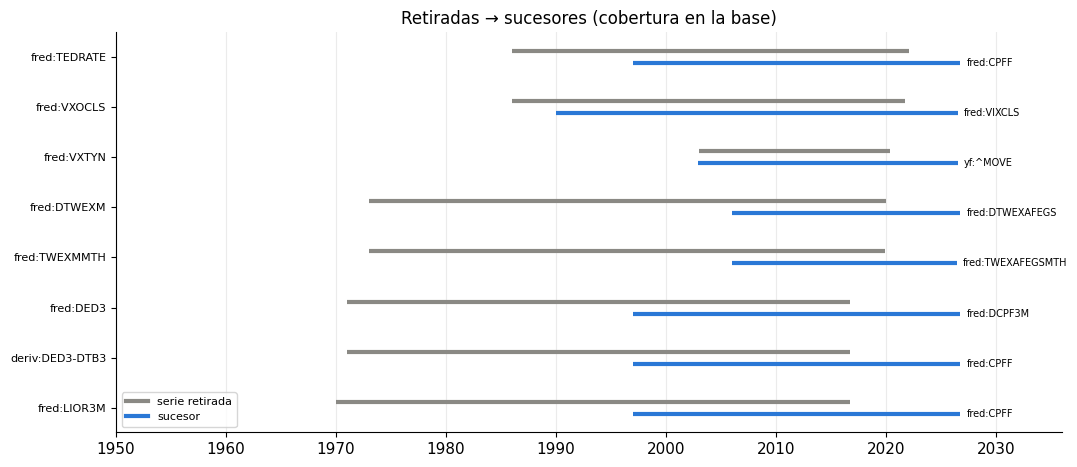

In [7]:
ret = COB[COB['estado'].isin(['retirada', 'capada'])].copy()
ret['sucesor_inicio'] = ret['sucesor'].map(COB.set_index('id')['inicio'])
ret['sucesor_fin'] = ret['sucesor'].map(COB.set_index('id')['fin'])
display(ret[['id', 'estado', 'frecuencia', 'inicio', 'fin', 'n_obs', 'sucesor', 'sucesor_inicio', 'sucesor_fin']]
        .sort_values(['estado', 'fin']).reset_index(drop=True))

con_sucesor = ret.dropna(subset=['sucesor']).sort_values('fin').reset_index(drop=True)
fig, ax = plt.subplots(figsize=(11, 0.45 * len(con_sucesor) + 1.2))
for i, f in con_sucesor.iterrows():
    ax.hlines(i + 0.12, pd.Timestamp(f['inicio']), pd.Timestamp(f['fin']), color=C_GRIS, lw=3)
    ax.hlines(i - 0.12, pd.Timestamp(f['sucesor_inicio']), pd.Timestamp(f['sucesor_fin']),
              color='#2a78d6', lw=3)
    ax.text(pd.Timestamp(f['sucesor_fin']) + pd.Timedelta(days=200), i - 0.12, f['sucesor'], va='center', fontsize=7)
ax.set_yticks(range(len(con_sucesor)))
ax.set_yticklabels(con_sucesor['id'], fontsize=8)
ax.set_xlim(pd.Timestamp('1950-01-01'), pd.Timestamp('2036-01-01'))
ax.grid(axis='y', visible=False)
ax.legend(handles=[Line2D([0], [0], color=C_GRIS, lw=3, label='serie retirada'),
                   Line2D([0], [0], color='#2a78d6', lw=3, label='sucesor')], loc='lower left', fontsize=8)
ax.set_title('Retiradas → sucesores (cobertura en la base)')
plt.tight_layout()
plt.show()

### El archivo de las OAS de ICE BofA

FRED sirve las OAS de ICE BofA solo desde el 2023-10-10. Se intentó recuperar la historia anterior con ALFRED
pidiendo un vintage previo al recorte (`vintage_dates=2026-03-31` y `realtime_start=realtime_end=2026-03-31`):
ese vintage también empieza en 2023-10-10, los vintages anteriores dan HTTP 400 y el primero conservado
es el 2023-10-10. La base guarda lo que FRED sirve hoy y, desde la primera descarga, el **archivo propio**: cada
día de descarga deja su fichero y la base une todas las descargas (la ventana móvil no pierde filas). Para
que el archivo no pierda historia basta una descarga dentro de cada ventana de tres años; la descarga
diaria (`python -m ingesta.mercados_series construir-base`, programable) solo hace falta para tener el
dato al día. Que la ventana sea móvil (y no un corte fijo en 2023-10-10) se confirmará con la descarga
siguiente.

In [8]:
oas = sorted(s for s, e in CAT.items() if e.get('publicador') == 'ice_bofa_fred')
display(COB.set_index('id').loc[oas, ['estado', 'inicio', 'fin', 'n_obs', 'n_huecos', 'lag_mediano_dias']])
ficha = json.loads((resultados_dir('mercados_series') / 'fichas' / 'ice_bofa_oas.json').read_text(encoding='utf-8'))
print('Ficha ice_bofa_oas: cobertura', ficha['cobertura_inicio'], 'a', ficha['cobertura_fin'])
print('Retraso:', ficha['retraso_publicacion'])
for nota in ficha['notas']:
    if 'ALFRED' in nota or 'archivo' in nota.lower():
        print('-', nota)

,estado,inicio,fin,n_obs,n_huecos,lag_mediano_dias
id,,,,,,
fred:BAMLC0A0CM,capada,2023-10-10,2026-10-08,785,0,1.0
fred:BAMLC0A0CMEY,capada,2023-10-10,2026-10-08,785,0,1.0
fred:BAMLC0A1CAAA,capada,2023-10-10,2026-10-08,786,0,1.0
fred:BAMLC0A4CBBB,capada,2023-10-10,2026-10-08,786,0,1.0
fred:BAMLH0A0HYM2,capada,2023-10-10,2026-10-08,786,0,1.0
fred:BAMLH0A0HYM2EY,capada,2023-10-10,2026-10-08,786,0,1.0
fred:BAMLH0A1HYBB,capada,2023-10-10,2026-10-08,786,0,1.0
fred:BAMLH0A3HYC,capada,2023-10-10,2026-10-08,786,0,1.0


Ficha ice_bofa_oas: cobertura 2023-10-10 a 2026-10-08
Retraso: hábil siguiente hacia las 09:10 NY (FRED last_updated 2026-10-09 09:08, 2026-10-09 09:09 con el dato de 2026-10-08): visible en la decisión de D+1. ALFRED fecha la vintage el mismo día del dato (BAMLC0A0CM {'D+0': 24}; BAMLH0A0HYM2 {'D+0': 24}), antes de la carga real: realtime_start no sirve para medir la hora de ICE
- Capada: la historia propia empieza en la primera descarga del archivo; cada descarga diaria se conserva y tabla_fred_sustitutos une todas (primer valor visto por fecha)
- Historial anterior: ALFRED en el vintage 2026-03-31 (por vintage_dates y por realtime_start/realtime_end) también empieza en el primer vintage conservado; los vintages anteriores dan error (ver mediciones.historial_alfred). Variante con todas las vintages en una llamada (realtime_start=1776-07-04, realtime_end=9999-12-31, output_type=4): empieza en BAMLH0A0HYM2 2023-10-11, BAMLC0A0CM 2023-10-11. No se puede recuperar por FRED


## 7. El mismo día visto por `get_serie`

Dos fechas de decisión: la quiebra de Lehman (lunes 2008-09-15) y el lunes de pánico del COVID-19
(2020-03-16). Para cada serie, el último valor que `get_serie` devuelve a las 16:30 de Nueva York de ese día:
su fecha de referencia, cuándo se publicó y con qué método. El S&P 500 cierra a las 16:00 y ya se ve el mismo
día; el VIX (Cboe, 16:15) y el 10 años de H.15 se ven al día siguiente; el IPC y el paro llevan un retraso de
meses (`lag_fijo`, con aviso de posible fuga de revisiones hasta el bloque 3).

La tabla muestra solo fechas, método y número de avisos: los valores no se imprimen (licencias de FRED,
S&P, Moody's, Cboe y Shiller; al repositorio solo van metadatos).

In [9]:
CLAVE = ['SP500', 'VIX', 'DGS10', 'T10Y2Y', 'MOODYS_BAA_AAA_SPREAD', 'NFCI', 'CPIAUCSL', 'UNRATE',
         'ff:F3D.Mkt-RF', 'SHILLER_SP500_CAPE']
filas = []
for fecha in ('2008-09-15', '2020-03-16'):
    for sid in CLAVE:
        r = tools.get_serie(sid, fecha, base=BASE)
        u = r.ultimo()
        filas.append({'fecha_decision': fecha, 'id': sid, 'serie': r.serie,
                      'fecha_referencia': u['fecha_referencia'], 'fecha_publicacion': u['fecha_publicacion'],
                      'metodo': u['metodo_publicacion'], 'avisos': len(r.avisos)})
mismo_dia = pd.DataFrame(filas)
mismo_dia['dias_desde_referencia'] = (pd.to_datetime(mismo_dia['fecha_decision'])
                                      - pd.to_datetime(mismo_dia['fecha_referencia'])).dt.days
display(mismo_dia.set_index(['fecha_decision', 'id']))

serie fecha_referencia fecha_publicacion          metodo  avisos  dias_desde_referencia
fecha_decision id                                                                                                                      
2008-09-15     SP500                         yf:^GSPC       2008-09-15        2008-09-15  cierre_mercado       0                      0
               VIX                        fred:VIXCLS       2008-09-12        2008-09-13  cierre_mercado       0                      3
               DGS10                       fred:DGS10       2008-09-12        2008-09-15      calendario       0                      3
               T10Y2Y                     fred:T10Y2Y       2008-09-12        2008-09-15      calendario       0                      3
               MOODYS_BAA_AAA_SPREAD  deriv:DBAA-DAAA       2008-09-12        2008-09-15        derivada       0                      3
               NFCI                         fred:NFCI       2008-09-05        2008-09-10        lag_fijo       3                     10
               CPIAUCSL                 fred:CPIAUCSL       2008-07-01        2008-09-01        lag_fijo       2                     76
               UNRATE                     fred:UNRATE       2008-07-01        2008-09-01        lag_fijo       2                     76
               ff:F3D.Mkt-RF            ff:F3D.Mkt-RF       2008-07-31        2008-09-14         fichero       1                     46
               SHILLER_SP500_CAPE        shiller:CAPE       2008-07-01        2008-09-01         fichero       1                     76
2020-03-16     SP500                         yf:^GSPC       2020-03-16        2020-03-16  cierre_mercado       0                      0
               VIX                        fred:VIXCLS       2020-03-13        2020-03-14  cierre_mercado       0                      3
               DGS10                       fred:DGS10       2020-03-13        2020-03-16      calendario       0                      3
               T10Y2Y                     fred:T10Y2Y       2020-03-13        2020-03-14      calendario       1                      3
               MOODYS_BAA_AAA_SPREAD  deriv:DBAA-DAAA       2020-03-13        2020-03-16        derivada       0                      3
               NFCI                         fred:NFCI       2020-03-06        2020-03-11        lag_fijo       3                     10
               CPIAUCSL                 fred:CPIAUCSL       2020-01-01        2020-03-01        lag_fijo       2                     75
               UNRATE                     fred:UNRATE       2020-01-01        2020-03-01        lag_fijo       2                     75
               ff:F3D.Mkt-RF            ff:F3D.Mkt-RF       2020-01-31        2020-03-16         fichero       1                     45
               SHILLER_SP500_CAPE        shiller:CAPE       2020-01-01        2020-03-01         fichero       1                     75

In [10]:
# Una ETF de la Fase 1 no está en la base: get_serie remite a get_precios (bloque 6).
try:
    tools.get_serie('SP500_CAPWEIGHT_ETF', '2020-03-16', base=BASE)
except KeyError as e:
    print('KeyError:', e)
r = tools.get_serie('CPIAUCSL', '2020-03-16', base=BASE)
print('\nAvisos de CPIAUCSL el 2020-03-16:')
for a in r.avisos:
    print('-', a)

KeyError: "serie 'yf:SPY' (alias 'SP500_CAPWEIGHT_ETF') excluida de la base de series: ETF de yfinance con niveles ajustados a posteriori (auto_adjust=True). Usa get_precios('SPY', fecha), que reconstruye el ajuste con lo conocido en la fecha (bloque 6)"

Avisos de CPIAUCSL el 2020-03-16:
- fecha de publicación por regla en 877 periodos (método lag_fijo: retraso declarado en lags.yaml, no la fecha real de cada publicación; corregido con la primera vintage de ALFRED en 0 periodos)
- serie revisable con los valores del último vintage o edición en 877 periodos: posible fuga de revisiones (no son los valores que se conocían en su fecha)


## 8. Fechas de publicación medidas, índices reconstruidos y anomalías

Las reglas (`lag_fijo`, publicadores) fallan cuando la publicación real se retrasa: cierres del Gobierno
federal (1995-96, 2013, 2018-19 y 2025-26), Moody's fuera de FRED entre octubre de 2016 y marzo de 2017, las
medias mensuales de H.15 que hasta 2016 salían en la edición semanal, el LIBOR con una semana de retraso en
FRED (TEDRATE)... `python -m ingesta.mercados_series excepciones-alfred` contrasta cada regla con la primera
vintage de ALFRED (`output_type=4`) de cada observación posterior a la primera vintage de la serie, y la base
usa `fecha_publicacion = max(regla, ALFRED)` (`config/excepciones_publicacion.csv`). Antes de la primera
vintage de cada serie no hay medición.

Además: los índices construidos hacia atrás (NFCI desde 1971, publicado desde 2011) llevan una nota y
`get_serie` avisa; los picos aislados que se revierten, los cierres en fin de semana y las rachas planas se
anotan en la `nota` sin tocar valores.

In [11]:
tablas_dir = resultados_dir('mercados_series') / 'tablas'
medida = pd.read_csv(tablas_dir / 'publicacion_alfred_medida.csv')
medida = medida[pd.to_numeric(medida['n_cubiertas'], errors='coerce').fillna(0) > 0]
cols = ['serie', 'regla', 'primera_vintage', 'n_cubiertas', 'n_fugas', 'fuga_max_dias', 'holgura_mediana_dias']
print(f'{len(medida)} series medidas en ALFRED; {int(medida["n_fugas"].sum()):,} de '
      f'{int(medida["n_cubiertas"].sum()):,} periodos publicados después de la regla')
display(medida.sort_values('n_fugas', ascending=False)[cols].head(20).reset_index(drop=True))

nota = BASE['nota'].fillna('')
corregidas = BASE[nota.str.contains(cat_mod.NOTA_EXCEPCION, regex=False)]
print(f'Filas de la base con la fecha retrasada a la primera vintage de ALFRED: {len(corregidas):,} '
      f'en {corregidas["serie"].nunique()} series')
cierres = corregidas[corregidas['serie'].isin(['fred:UNRATE', 'fred:PAYEMS', 'fred:GDPC1', 'fred:HOUST'])
                     & (corregidas['fecha_referencia'] >= '2025-06-01')]
display(cierres[['serie', 'fecha_referencia', 'fecha_publicacion']].reset_index(drop=True))

63 series medidas en ALFRED; 12,375 de 65,065 periodos publicados después de la regla


,serie,regla,primera_vintage,n_cubiertas,n_fugas,fuga_max_dias,holgura_mediana_dias
0,fred:TEDRATE,fred_calculadas_dia_siguiente,2014-01-27,1950.0,1950.0,8.0,-6.0
1,fred:DCPF3M,fed_cp,2006-03-22,4439.0,1497.0,5.0,0.0
2,fred:T5YIFR,fred_tesoro_calculadas,2014-01-27,3179.0,1360.0,6.0,0.0
3,fred:T10Y3M,fred_tesoro_calculadas,2014-01-27,3179.0,1360.0,6.0,0.0
4,fred:T10YIE,fred_tesoro_calculadas,2014-01-27,3179.0,1360.0,6.0,0.0
5,fred:T10Y2Y,fred_tesoro_calculadas,2014-01-27,3179.0,1360.0,6.0,0.0
6,fred:T5YIE,fred_tesoro_calculadas,2014-01-27,3179.0,1360.0,6.0,0.0
7,fred:BAA10Y,fred_calculadas_dia_siguiente,2014-01-27,3172.0,198.0,162.0,0.0
8,fred:BAA,1D desde el fin de mes,1996-12-03,358.0,188.0,141.0,-1.0
9,fred:AAA,1D desde el fin de mes,1996-12-03,358.0,188.0,141.0,-1.0


Filas de la base con la fecha retrasada a la primera vintage de ALFRED: 12,520 en 54 series


,serie,fecha_referencia,fecha_publicacion
0,fred:GDPC1,2025-07-01,2025-12-23
1,fred:GDPC1,2025-10-01,2026-02-20
2,fred:HOUST,2025-09-01,2026-01-09
3,fred:HOUST,2025-10-01,2026-01-09
4,fred:HOUST,2025-11-01,2026-02-18
5,fred:HOUST,2025-12-01,2026-02-18
6,fred:HOUST,2026-01-01,2026-03-12
7,fred:HOUST,2026-02-01,2026-04-29
8,fred:PAYEMS,2025-09-01,2025-11-20
9,fred:PAYEMS,2025-10-01,2025-12-16


In [12]:
rec = BASE[nota.str.contains(cat_mod.NOTA_RECONSTRUIDA, regex=False)]
print('Filas publicadas antes de la creación de su índice (reconstruidas hacia atrás):')
display(rec.groupby('serie').agg(filas=('fecha_referencia', 'size'), desde=('fecha_referencia', 'min'),
                                 hasta=('fecha_referencia', 'max')))
anom = pd.read_csv(tablas_dir / 'anomalias_series.csv')
print(f'Anomalías anotadas (solo nota, valores intactos): {len(anom)}')
display(anom.groupby(['tipo', 'serie']).agg(n=('fecha_referencia', 'size'), primera=('fecha_referencia', 'min'),
                                            ultima=('fecha_referencia', 'max')).reset_index())
ff = json.loads((resultados_dir('mercados_series') / 'fichas' / 'ken_french.json').read_text(encoding='utf-8'))
for n in CAT['ff:MOMD.Mom']['notas']:
    if 'revisión completa' in n:
        print('ff:MOMD.Mom:', n)

Filas publicadas antes de la creación de su índice (reconstruidas hacia atrás):


,filas,desde,hasta
serie,,,
fred:ANFCI,2106,1971-01-08,2011-05-13
fred:NFCI,2106,1971-01-08,2011-05-13
fred:NFCICREDIT,2164,1971-01-08,2012-06-22
fred:NFCILEVERAGE,2164,1971-01-08,2012-06-22
fred:NFCIRISK,2164,1971-01-08,2012-06-22
fred:SAHMCURRENT,845,1949-03-01,2019-07-01
fred:SAHMREALTIME,716,1959-12-01,2019-07-01
fred:STLFSI4,1505,1993-12-31,2022-10-28


Anomalías anotadas (solo nota, valores intactos): 582


,tipo,serie,n,primera,ultima
0,fin_de_semana,fred:VXDCLS,1,2021-07-25,2021-07-25
1,fin_de_semana,fred:VXNCLS,1,2003-08-24,2003-08-24
2,pico,fred:EVZCLS,2,2024-07-15,2024-07-16
3,pico,fred:OVXCLS,1,2011-11-25,2011-11-25
4,pico,fred:VXDCLS,7,2021-07-13,2025-10-16
5,pico,fred:VXEEMCLS,3,2021-04-22,2022-03-28
6,racha,fred:DED3,567,2013-03-05,2015-12-03


ff:MOMD.Mom: revisión completa entre ediciones (medido en el bloque 2): la edición de data/raw (2026-07-20) y la del 2026-09-25 difieren en 14699 de 26152 días comunes (máx. 3,79 pp; correlación 0,994; no es un desfase de fechas). La base guarda la última: los valores antiguos no son los que se conocían en su fecha


## 9. Conclusiones

- La base une `data/raw` de la Fase 1, los sustitutos de FRED y las fuentes académicas con una sola fuente
  por serie y fecha de publicación en todas las filas (inventario y cobertura en las secciones 1 a 3).
- Las reglas de publicación no bastan en los periodos anómalos: la medición con ALFRED (sección 8) encontró
  fugas en los cierres del Gobierno (paro y empleo de septiembre de 2025 publicados el 2025-11-20; PIB del
  tercer trimestre de 2025 el 2025-12-23), en Moody's 2016-17, en las medias mensuales de H.15 anteriores a
  2017 y en las series que FRED calcula con LIBOR. La base las corrige observación a observación; antes de
  la primera vintage de cada serie la regla sigue siendo una aproximación.
- Siguen abiertas: las revisiones (las revisables de FRED llevan el último vintage hasta el bloque 3; las
  académicas, la última edición, con un archivo propio de ediciones desde el 2026-10-12: el momentum diario
  de French cambió en más de la mitad de los días entre dos ediciones), los índices reconstruidos hacia atrás
  (aviso, no se ocultan) y los errores de la fuente anotados como anomalías.
- El historial de las OAS de ICE BofA anterior al 2023-10-10 no se puede recuperar por FRED ni por ALFRED:
  solo el archivo propio lo conservará hacia delante.